# 04 — Feature Engineering

**Goal:** build the leakage-safe feature set from `src/features/feature_pipeline.py`
and inspect what each feature actually represents.

See `docs/DATA_LEAKAGE_AUDIT.md` for the full leakage-prevention rationale —
this notebook focuses on *what* the features are, not the safety proof
(that's notebook 05).

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'GLD' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['GLD', 'MSFT']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['BND', 'AAPL', 'SPY']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.features.feature_pipeline import build_features_for_asset, FEATURE_SPEC

spec_df = pd.DataFrame(FEATURE_SPEC).T
spec_df.index.name = "feature"
spec_df

,formula,lookback_days,leakage_risk
feature,,,
ret_1d,P_t/P_(t-1) - 1,1,none: uses only t and t-1
ret_5d,P_t/P_(t-5) - 1,5,none
ret_10d,P_t/P_(t-10) - 1,10,none
ret_20d,P_t/P_(t-20) - 1,20,none
ret_60d,P_t/P_(t-60) - 1,60,none
vol_5d,"std(daily log returns, 5d window)",5,none: rolling window ends at t
vol_10d,"std(daily log returns, 10d window)",10,none
vol_20d,"std(daily log returns, 20d window)",20,none
vol_60d,"std(daily log returns, 60d window)",60,none


In [3]:
ticker = TICKERS[0]
asset_prices = price_panel[[ticker]].reset_index()
asset_prices.columns = ["date", "adj_close"]
asset_prices["volume"] = 1_000_000

market_prices = price_panel["SPY"] if "SPY" in price_panel.columns else None
combined = pd.DataFrame({"date": asset_prices["date"], "adj_close": asset_prices["adj_close"], "volume": asset_prices["volume"]})

feats = build_features_for_asset(combined, market_prices=market_prices)
print(feats.shape)
feats.tail()

(2004, 19)


,date,ret_1d,ret_5d,ret_10d,ret_20d,ret_60d,vol_5d,vol_10d,vol_20d,vol_60d,vol_ratio_20_60,momentum_20d,ma_ratio_20_60,rsi_14,rolling_drawdown,momentum_vol_interaction,volume_zscore_20d,beta_60d,corr_market_60d
1999,2026-08-31,0.032880,0.048774,0.062529,-0.009360,0.035525,0.018398,0.014414,0.018047,0.016188,1.114807,0.020765,0.991579,52.982272,-0.058471,0.000375,NaN,-0.269374,-0.173175
2000,2026-09-01,-0.011266,0.050375,0.042464,-0.044773,0.037602,0.017941,0.015396,0.017148,0.016161,1.061086,0.011658,0.988636,49.875968,-0.069077,0.000200,NaN,-0.221109,-0.142155
2001,2026-09-02,0.009079,0.040028,0.061225,-0.044622,0.034301,0.017216,0.014748,0.017154,0.016127,1.063634,0.023282,0.985729,54.244161,-0.060626,0.000399,NaN,-0.216587,-0.139495
2002,2026-09-03,0.016597,0.042109,0.076480,-0.020148,0.058896,0.017430,0.015032,0.017573,0.016225,1.083075,0.041380,0.983740,56.487389,-0.045035,0.000727,NaN,-0.217832,-0.138943
2003,2026-09-04,-0.001086,0.046482,0.080132,-0.008293,0.060671,0.016703,0.014771,0.017341,0.016220,1.069143,0.040702,0.982353,73.027097,-0.046072,0.000706,NaN,-0.209279,-0.134884


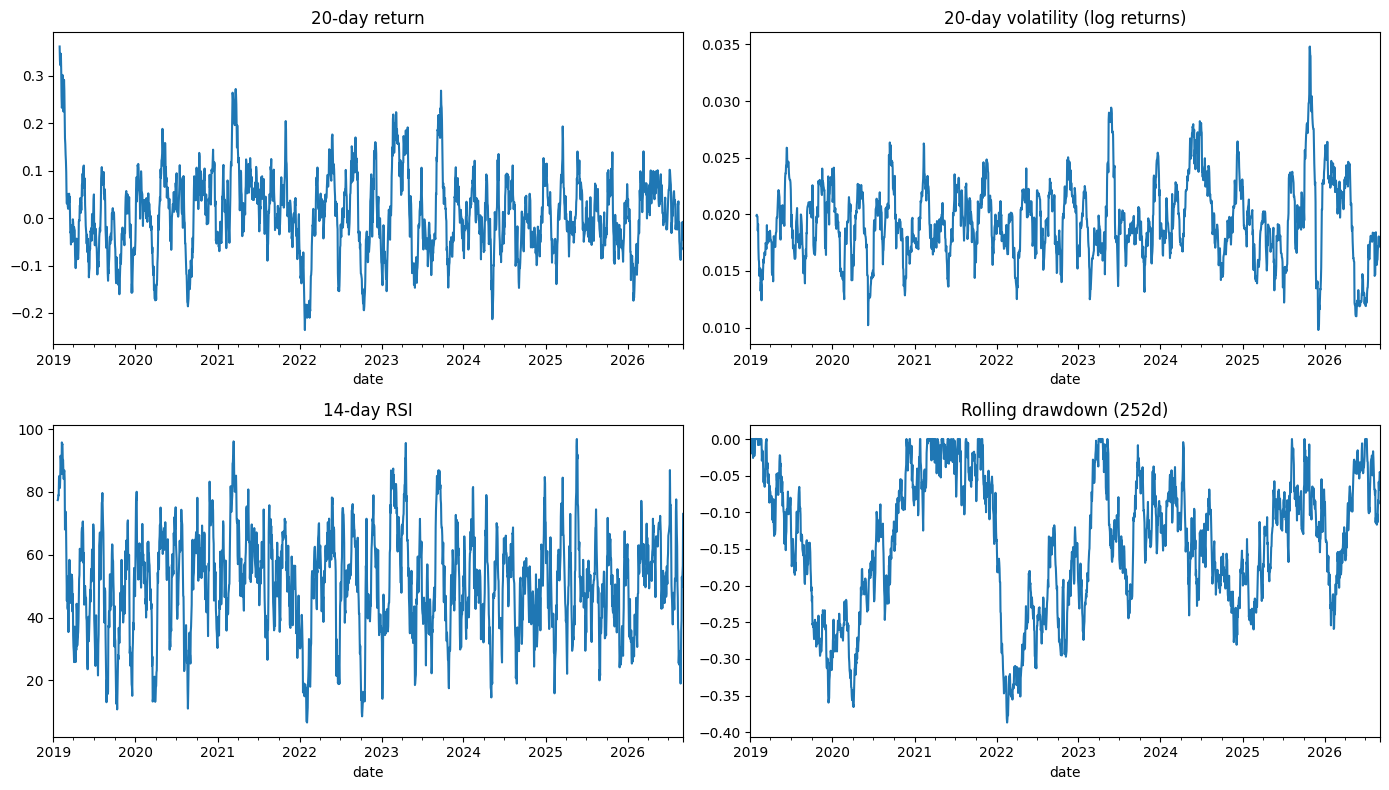

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
feats.set_index("date")["ret_20d"].plot(ax=axes[0, 0], title="20-day return")
feats.set_index("date")["vol_20d"].plot(ax=axes[0, 1], title="20-day volatility (log returns)")
feats.set_index("date")["rsi_14"].plot(ax=axes[1, 0], title="14-day RSI")
feats.set_index("date")["rolling_drawdown"].plot(ax=axes[1, 1], title="Rolling drawdown (252d)")
plt.tight_layout()
plt.show()

## Takeaways

- Every feature is a **trailing** window ending at date t — no feature ever uses data from after t.
- `beta_60d` / `corr_market_60d` need a market series; when a market ticker like SPY is included, they're computed against it.
- Continue to **05 — Leakage Audit Demonstration** to see these guarantees proven, not just asserted.